In [21]:
import pandas as pd
import seaborn as sns
import numpy as np
import tensorflow as tf
import tensorboard as tb
import matplotlib.pyplot as plt

from data_utils import load_clean

In [22]:
df = load_clean("../dataset/Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt")

df.head()

../dataset/Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt: 69125 rows, fixed 652 blended rows


,Timer(ms),Loc(m),Speed (m/s),East(m),North(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,...,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),RBCSV_60(cf),posneg,vaikeus,muu,Speed_kmh
0,45476731.0,3767.52,0.035,426290.475,7414101.054,107.049,1.6195,-1.7959,13.5969,0.42274,...,9.84059,-0.00239,0.00271,-0.00435,0.87092,0.85334,0,0,0,0.126
1,45476733.5,3767.52,0.035,426290.475,7414101.054,107.049,1.6197,-1.7954,13.5971,0.37197,...,9.83939,-0.00394,0.00529,-0.00295,0.87092,0.85334,0,0,0,0.126
2,45476728.5,3767.52,0.035,426290.475,7414101.054,107.048,1.6192,-1.7961,13.5968,0.39457,...,9.83537,-0.00354,0.00251,-0.00404,0.87092,0.85334,0,0,0,0.126
3,45476736.0,3767.52,0.035,426290.475,7414101.054,107.049,1.6196,-1.7955,13.5979,0.41483,...,9.83531,-0.00540,0.00077,0.00153,0.87092,0.85334,0,0,0,0.126
4,45476726.0,3767.52,0.035,426290.475,7414101.054,107.048,1.6190,-1.7962,13.5968,0.39042,...,9.82614,-0.00743,-0.00130,-0.00236,0.87092,0.85334,0,0,0,0.126


In [23]:
df.shape

(69125, 21)

In [24]:
df.dtypes

Timer(ms)       float64
Loc(m)          float64
Speed (m/s)     float64
East(m)         float64
North(m)        float64
CElev(m)        float64
Roll(deg)       float64
Pitch(deg)      float64
Yaw(deg)        float64
AccX            float64
AccY            float64
AccZ            float64
GyrX            float64
GyrY            float64
GyrZ            float64
RBCSV_80(cf)    float64
RBCSV_60(cf)    float64
posneg            int64
vaikeus           int64
muu               int64
Speed_kmh       float64
dtype: object

In [25]:
df.describe()

,Timer(ms),Loc(m),Speed (m/s),East(m),North(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,...,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),RBCSV_60(cf),posneg,vaikeus,muu,Speed_kmh
count,6.912500e+04,69125.000000,69124.000000,69125.000000,6.912500e+04,69125.000000,69125.000000,69125.000000,69125.000000,69125.000000,...,69125.000000,69125.000000,69125.000000,69125.000000,69125.000000,69125.000000,69125.000000,69125.000000,69125.000000,69124.000000
mean,4.555896e+07,5267.249186,18.386808,425104.126712,7.414997e+06,109.938764,1.622041,-2.865558,141.837017,0.506266,...,9.817057,-0.005219,0.001064,-0.000795,0.526175,0.451702,0.185389,0.722300,0.417461,66.192508
std,4.988703e+04,1025.478420,6.956886,848.917079,5.593478e+02,4.590331,1.038126,1.137758,30.424741,1.036052,...,1.561488,0.040699,0.057155,0.048169,0.466859,0.431190,0.388615,1.639838,0.981104,25.044791
min,4.547255e+07,3767.520000,0.035000,423656.376000,7.414101e+06,105.584000,-3.996900,-19.365800,-4.981100,-5.397300,...,1.286240,-0.408610,-0.502450,-0.273570,0.064660,0.038440,0.000000,0.000000,0.000000,0.126000
25%,4.551576e+07,4339.763000,18.673750,424357.319000,7.414484e+06,106.446000,1.255200,-3.392900,142.071400,0.081400,...,9.177630,-0.022360,-0.020760,-0.010010,0.223330,0.181100,0.000000,0.000000,0.000000,67.225500
50%,4.555896e+07,5243.771000,21.593000,425190.873000,7.415091e+06,107.473000,1.760800,-2.773600,143.048400,0.440220,...,9.816790,-0.004330,0.000640,-0.003610,0.369370,0.290900,0.000000,0.000000,0.000000,77.734800
75%,4.560216e+07,6171.601000,22.439000,425863.885000,7.415485e+06,114.431000,2.274300,-2.221800,157.811300,0.926290,...,10.436420,0.013690,0.022440,0.004070,0.703700,0.590450,0.000000,0.000000,0.000000,80.780400
max,4.564536e+07,6937.284000,23.036000,426290.512000,7.415796e+06,120.000000,4.268600,7.687100,174.963900,4.918070,...,23.703130,0.491990,0.416060,0.419170,2.699610,2.781890,1.000000,5.000000,5.000000,82.929600


In [26]:
df.isna().sum()

Timer(ms)       0
Loc(m)          0
Speed (m/s)     1
East(m)         0
North(m)        0
CElev(m)        0
Roll(deg)       0
Pitch(deg)      0
Yaw(deg)        0
AccX            0
AccY            0
AccZ            0
GyrX            0
GyrY            0
GyrZ            0
RBCSV_80(cf)    0
RBCSV_60(cf)    0
posneg          0
vaikeus         0
muu             0
Speed_kmh       1
dtype: int64

In [27]:
# for name, df in data.items():
#     if "Iisingintie" in name:
#         heave = df["muu"] == 1
#         starts = df.loc[heave & ~heave.shift(fill_value=False), "Loc(m)"]
#         print(name.split("_")[2], starts.round().tolist())

Columns with empty values: {'Speed (m/s)': 1, 'Speed_kmh': 1}
Row numbers: [2870] out of 69125
Time between rows (ms): 2.5


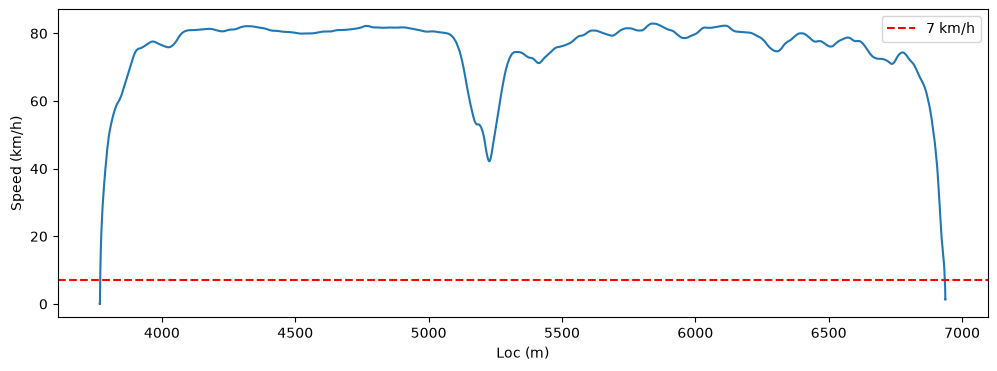

In [28]:
# 1. Where are the 2 empty values?
empty = df.isna()
print("Columns with empty values:", empty.sum()[empty.sum() > 0].to_dict())
print("Row numbers:", df.index[empty.any(axis=1)].tolist(), "out of", len(df))

# 2. How often does the sensor record?
print("Time between rows (ms):", df["Timer(ms)"].diff().median())

# 3. Where is the car slow?
plt.figure(figsize=(12, 4))
plt.plot(df["Loc(m)"], df["Speed_kmh"])
plt.axhline(7, color="red", linestyle="--", label="7 km/h")
plt.xlabel("Loc (m)")
plt.ylabel("Speed (km/h)")
plt.legend()
plt.show()

In [29]:
# import matplotlib.pyplot as plt
# from pathlib import Path

# files = sorted(Path("../dataset").glob("*.txt"))
# fig, axes = plt.subplots(4, 2, figsize=(14, 12))

# for ax, f in zip(axes.flat, files):
#     df = load_clean(f)
#     ax.plot(df["Loc(m)"], df["Speed_kmh"])
#     ax.axhline(7, color="red", linestyle="--")
#     ax.set_title(f.name.split("_RDMC")[0], fontsize=9)

# plt.tight_layout()
# plt.show()